In [ ]:
from google.colab import files

uploaded = files.upload()

Saving BBMP_complaints_2023_2024.csv to BBMP_complaints_2023_2024.csv
Saving BBMP_status_summary.csv to BBMP_status_summary.csv
Saving bengaluru_monthly_rainfall.csv to bengaluru_monthly_rainfall.csv
Saving bengaluru_ward_population_2011.csv to bengaluru_ward_population_2011.csv


In [ ]:
import os

os.listdir()

['.config',
 'BBMP_complaints_2023_2024.csv',
 'bengaluru_monthly_rainfall.csv',
 'bengaluru_ward_population_2011.csv',
 'BBMP_status_summary.csv',
 'sample_data']

In [ ]:
import pandas as pd

complaints = pd.read_csv("BBMP_complaints_2023_2024.csv")

rainfall = pd.read_csv("bengaluru_monthly_rainfall.csv")

population = pd.read_csv("bengaluru_ward_population_2011.csv")

In [ ]:
print("Complaints:", complaints.shape)
print("Rainfall:", rainfall.shape)
print("Population:", population.shape)

Complaints: (326156, 7)
Rainfall: (1500, 4)
Population: (198, 12)


In [ ]:
print("Complaints columns:", complaints.columns.tolist())

print("Rainfall columns:", rainfall.columns.tolist())

print("Population columns:", population.columns.tolist())

Complaints columns: ['complaint_id', 'category', 'subcategory', 'grievance_date', 'ward', 'status', 'year']
Rainfall columns: ['date', 'year', 'month', 'rainfall_mm']
Population columns: ['ward_number', 'ward_name', 'population_2011', 'Male', 'Female', 'SC Population', 'SC male', 'SC Female', 'ST Population', 'ST Male', 'ST Female', 'Assembly constituency']


In [ ]:
print("Complaints:")
print(complaints.isnull().sum())

print("\nRainfall:")
print(rainfall.isnull().sum())

print("\nPopulation:")
print(population.isnull().sum())

Complaints:
complaint_id      0
category          0
subcategory       0
grievance_date    0
ward              0
status            0
year              0
dtype: int64

Rainfall:
date           0
year           0
month          0
rainfall_mm    1
dtype: int64

Population:
ward_number              0
ward_name                0
population_2011          0
Male                     0
Female                   0
SC Population            0
SC male                  0
SC Female                0
ST Population            0
ST Male                  0
ST Female                0
Assembly constituency    0
dtype: int64


In [ ]:
rainfall[rainfall['rainfall_mm'].isnull()]

,date,year,month,rainfall_mm
599,1950-12-01,1950,12,NaN


In [ ]:
rainfall = rainfall[rainfall['year'].isin([2023, 2024])].copy()

In [ ]:
rainfall.shape

(24, 4)

In [ ]:
print("Complaints:", complaints.duplicated().sum())
print("Rainfall:", rainfall.duplicated().sum())
print("Population:", population.duplicated().sum())

Complaints: 0
Rainfall: 0
Population: 0


In [ ]:
complaints['complaint_id'].duplicated().sum()

np.int64(0)

In [ ]:
complaints.dtypes

,0
complaint_id,int64
category,object
subcategory,object
grievance_date,object
ward,object
status,object
year,int64


In [ ]:
complaints['grievance_date'] = pd.to_datetime(complaints['grievance_date'])

In [ ]:
complaints.head()

,complaint_id,category,subcategory,grievance_date,ward,status,year
0,20437520,Road Maintenance(Engg),Road cutting,2023-12-31 11:29:00,Chamrajpet,Closed,2023
1,20437519,Electrical,Street Light Not Working,2023-12-31 11:26:00,Jnanabharathi Ward,Closed,2023
2,20437518,Forest,obstructions Branches / Trees.,2023-12-31 11:15:00,Nandini Layout,Closed,2023
3,20437517,Electrical,Street Light Not Working,2023-12-31 11:13:00,Nandini Layout,Closed,2023
4,20437516,Electrical,Street Light Not Working,2023-12-31 11:02:00,Ganeshmandira Ward,Closed,2023


In [ ]:
complaints['month'] = complaints['grievance_date'].dt.month

In [ ]:
complaints

,complaint_id,category,subcategory,grievance_date,ward,status,year,month
0,20437520,Road Maintenance(Engg),Road cutting,2023-12-31 11:29:00,Chamrajpet,Closed,2023,12
1,20437519,Electrical,Street Light Not Working,2023-12-31 11:26:00,Jnanabharathi Ward,Closed,2023,12
2,20437518,Forest,obstructions Branches / Trees.,2023-12-31 11:15:00,Nandini Layout,Closed,2023,12
3,20437517,Electrical,Street Light Not Working,2023-12-31 11:13:00,Nandini Layout,Closed,2023,12
4,20437516,Electrical,Street Light Not Working,2023-12-31 11:02:00,Ganeshmandira Ward,Closed,2023,12
...,...,...,...,...,...,...,...,...
326151,20437525,Electrical,Street Light Not Working,2024-01-01 01:33:00,Ramamurthy Nagar,Closed,2024,1
326152,20437524,Solid Waste (Garbage) Related,Garbage transfer not as per norms & area not k...,2024-01-01 01:00:00,Doddanekkundi,Closed,2024,1
326153,20437523,Electrical,Street Light Not Working,2024-01-01 12:13:00,Sudam Nagar,Closed,2024,1
326154,20437522,Solid Waste (Garbage) Related,Garbage transfer not as per norms & area not k...,2024-01-01 12:05:00,Doddanekkundi,Closed,2024,1


In [ ]:
complaints[['grievance_date', 'year', 'month']].head()

,grievance_date,year,month
0,2023-12-31 11:29:00,2023,12
1,2023-12-31 11:26:00,2023,12
2,2023-12-31 11:15:00,2023,12
3,2023-12-31 11:13:00,2023,12
4,2023-12-31 11:02:00,2023,12


In [ ]:
monthly_complaints = complaints.groupby(['year','month']).size().reset_index(name = 'total_complaints')

In [ ]:
rainfall.head()

,date,year,month,rainfall_mm
1464,2023-01-01,2023,1,0.0
1465,2023-02-01,2023,2,0.0
1466,2023-03-01,2023,3,8.4
1467,2023-04-01,2023,4,28.2
1468,2023-05-01,2023,5,305.5


In [ ]:
monthly_data = pd.merge(monthly_complaints,rainfall[['year', 'month', 'rainfall_mm']],on=['year', 'month'],how='left')

monthly_data.head()

,year,month,total_complaints,rainfall_mm
0,2023,1,6999,0.0
1,2023,2,7145,0.0
2,2023,3,8105,8.4
3,2023,4,5902,28.2
4,2023,5,10182,305.5


In [ ]:
print(monthly_data.shape)

print(monthly_data.isnull().sum())

print(monthly_data['total_complaints'].sum())

(24, 4)
year                0
month               0
total_complaints    0
rainfall_mm         0
dtype: int64
326156


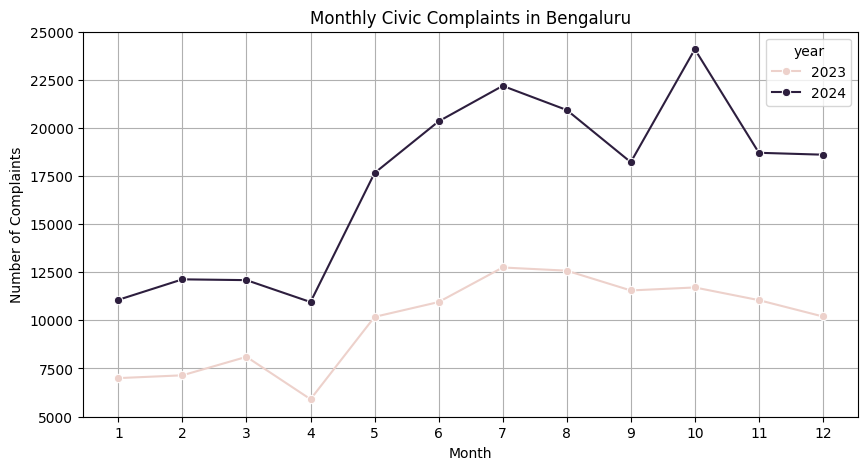

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

sns.lineplot(data=monthly_data,x='month',y='total_complaints',hue='year', marker='o')

plt.title('Monthly Civic Complaints in Bengaluru')
plt.xlabel('Month')
plt.ylabel('Number of Complaints')
plt.xticks(range(1, 13))
plt.grid(True)
plt.show()

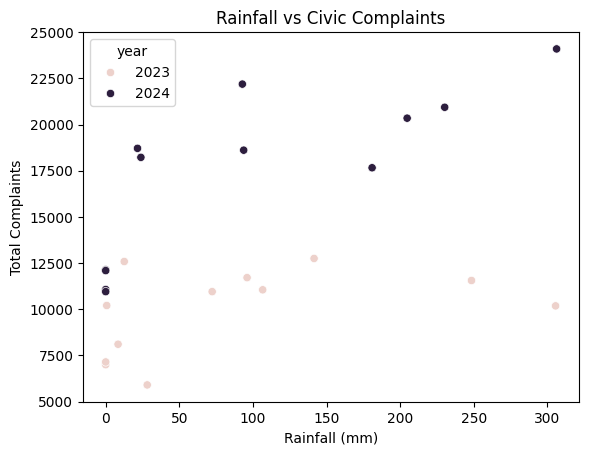

In [ ]:
#To check does months with higher rainfall has more complaints?
sns.scatterplot(
    data=monthly_data,
    x='rainfall_mm',
    y='total_complaints',
    hue='year'
)

plt.title('Rainfall vs Civic Complaints')
plt.xlabel('Rainfall (mm)')
plt.ylabel('Total Complaints')
plt.show()

In [ ]:
monthly_data[['rainfall_mm', 'total_complaints']].corr()

,rainfall_mm,total_complaints
rainfall_mm,1.000000,0.485046
total_complaints,0.485046,1.000000


In [ ]:
monthly_data.groupby('year')[['rainfall_mm', 'total_complaints']].corr()

rainfall_mm  total_complaints
year                                                
2023 rainfall_mm          1.000000          0.440912
     total_complaints     0.440912          1.000000
2024 rainfall_mm          1.000000          0.788021
     total_complaints     0.788021          1.000000

In [ ]:
ward_complaints = complaints.groupby('ward').size().reset_index(name='total_complaints')

ward_complaints = ward_complaints.sort_values(
    by='total_complaints',
    ascending=False
)

ward_complaints.head(10)

,ward,total_complaints
87,Jnanabharathi Ward,7637
71,Horamavu,7016
66,Hemmigepura,6501
148,Rajarajeshwari Nagar,6450
17,Begur,6137
79,Jakkur,6054
178,Thanisandra,5926
18,Bellandur,5771
179,Ullalu,5127
70,Hoodi,4834


In [ ]:
category_complaints = complaints.groupby('category').size().reset_index(name='total_complaints')

category_complaints = category_complaints.sort_values(
    by='total_complaints',
    ascending=False
)

category_complaints.head(10)

,category,total_complaints
6,Electrical,127047
25,Solid Waste (Garbage) Related,85968
23,Road Maintenance(Engg),42874
9,Health Dept,18457
8,Forest,17483
31,veterinary,8167
22,Road Infrastructure,7506
16,Others,3281
27,Town Planning,3139
26,Storm Water Drain(SWD),2610


In [ ]:
ward_category = complaints.groupby(
    ['ward', 'category']
).size().reset_index(name='total_complaints')

ward_category.head(10)

,ward,category,total_complaints
0,A.Narayanapura,Advertisement,4
1,A.Narayanapura,Call Center,2
2,A.Narayanapura,E khata / Khata services,5
3,A.Narayanapura,Electrical,238
4,A.Narayanapura,Forest,12
5,A.Narayanapura,Health Dept,112
6,A.Narayanapura,Information Technology,5
7,A.Narayanapura,Lakes,9
8,A.Narayanapura,Optical Fiber Cables (OFC),1
9,A.Narayanapura,Others,6


In [ ]:
dominant_category = ward_category.sort_values(
    by='total_complaints',
    ascending=False
)

dominant_category = dominant_category.drop_duplicates(
    subset='ward'
)

dominant_category.head(10)

,ward,category,total_complaints
1668,Jnanabharathi Ward,Electrical,4269
1257,Hemmigepura,Electrical,3555
3349,Ullalu,Electrical,3305
1511,Jakkur,Electrical,3004
329,Begur,Electrical,2807
1365,Horamavu,Electrical,2669
2770,Rajarajeshwari Nagar,Electrical,2551
763,Dodda Bidarkallu,Electrical,2480
3339,Thanisandra,Solid Waste (Garbage) Related,2165
3157,Someshwara,Solid Waste (Garbage) Related,2141


In [ ]:
ward_features = pd.crosstab(
    complaints['ward'],
    complaints['category']
)

ward_features.head()

category,Advertisement,BBMP Election Branch,CORONA COVID19,Call Center,E khata / Khata services,Education,Electrical,Estate,Forest,Health Dept,...,Road Infrastructure,Road Maintenance(Engg),Sanitation,Solid Waste (Garbage) Related,Storm Water Drain(SWD),Town Planning,Traffic Engineer Cell (TEC),Water Crisis,Welfare Schemes,veterinary
ward,,,,,,,,,,,,,,,,,,,,,
A.Narayanapura,4,0,0,2,5,0,238,0,12,112,...,28,180,2,322,4,4,2,0,2,29
Adugodi,0,0,0,0,0,0,247,0,44,82,...,7,40,0,136,3,1,0,1,0,16
Agaram,2,0,0,0,0,0,249,0,13,51,...,15,41,1,84,4,1,1,2,0,11
Agrahara Dasarahalli,12,0,0,0,2,0,89,0,78,33,...,19,65,1,104,0,6,0,0,0,13
Anjanapur,1,1,0,0,7,0,822,1,115,95,...,28,232,4,468,12,18,1,4,1,125


In [ ]:
ward_normalized = ward_features / ward_features.sum(axis=1).values[:, None]

In [ ]:
ward_normalized.head()

category,Advertisement,BBMP Election Branch,CORONA COVID19,Call Center,E khata / Khata services,Education,Electrical,Estate,Forest,Health Dept,...,Road Infrastructure,Road Maintenance(Engg),Sanitation,Solid Waste (Garbage) Related,Storm Water Drain(SWD),Town Planning,Traffic Engineer Cell (TEC),Water Crisis,Welfare Schemes,veterinary
ward,,,,,,,,,,,,,,,,,,,,,
A.Narayanapura,0.004090,0.000000,0.0,0.002045,0.005112,0.0,0.243354,0.000000,0.012270,0.114519,...,0.028630,0.184049,0.002045,0.329243,0.004090,0.004090,0.002045,0.000000,0.002045,0.029652
Adugodi,0.000000,0.000000,0.0,0.000000,0.000000,0.0,0.422222,0.000000,0.075214,0.140171,...,0.011966,0.068376,0.000000,0.232479,0.005128,0.001709,0.000000,0.001709,0.000000,0.027350
Agaram,0.003984,0.000000,0.0,0.000000,0.000000,0.0,0.496016,0.000000,0.025896,0.101594,...,0.029880,0.081673,0.001992,0.167331,0.007968,0.001992,0.001992,0.003984,0.000000,0.021912
Agrahara Dasarahalli,0.027650,0.000000,0.0,0.000000,0.004608,0.0,0.205069,0.000000,0.179724,0.076037,...,0.043779,0.149770,0.002304,0.239631,0.000000,0.013825,0.000000,0.000000,0.000000,0.029954
Anjanapur,0.000504,0.000504,0.0,0.000000,0.003530,0.0,0.414523,0.000504,0.057993,0.047907,...,0.014120,0.116994,0.002017,0.236006,0.006051,0.009077,0.000504,0.002017,0.000504,0.063036


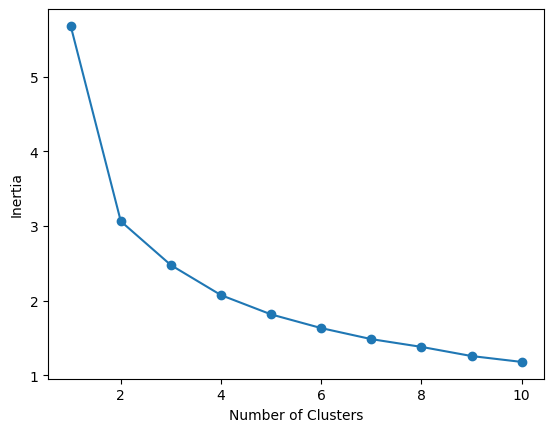

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(ward_normalized)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('Inertia')
plt.show()

In [ ]:
# kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)

# ward_features['cluster'] = kmeans.fit_predict(ward_normalized)

# ward_features.head()

category,Advertisement,BBMP Election Branch,CORONA COVID19,Call Center,E khata / Khata services,Education,Electrical,Estate,Forest,Health Dept,...,Road Maintenance(Engg),Sanitation,Solid Waste (Garbage) Related,Storm Water Drain(SWD),Town Planning,Traffic Engineer Cell (TEC),Water Crisis,Welfare Schemes,veterinary,cluster
ward,,,,,,,,,,,,,,,,,,,,,
A.Narayanapura,4,0,0,2,5,0,238,0,12,112,...,180,2,322,4,4,2,0,2,29,0
Adugodi,0,0,0,0,0,0,247,0,44,82,...,40,0,136,3,1,0,1,0,16,3
Agaram,2,0,0,0,0,0,249,0,13,51,...,41,1,84,4,1,1,2,0,11,1
Agrahara Dasarahalli,12,0,0,0,2,0,89,0,78,33,...,65,1,104,0,6,0,0,0,13,0
Anjanapur,1,1,0,0,7,0,822,1,115,95,...,232,4,468,12,18,1,4,1,125,3


In [ ]:
# ward_features['cluster'].value_counts()

,count
cluster,
3,74
0,53
1,38
2,33


In [ ]:
# ward_normalized['cluster'] = ward_features['cluster']

# cluster_summary = ward_normalized.groupby('cluster').mean()

# cluster_summary.T

cluster,0,1,2,3
category,,,,
Advertisement,0.006560,0.005217,0.007577,0.004344
BBMP Election Branch,0.000092,0.000067,0.000176,0.000122
CORONA COVID19,0.000175,0.000208,0.000362,0.000392
Call Center,0.000512,0.000195,0.000177,0.000641
E khata / Khata services,0.001202,0.002086,0.001079,0.001100
Education,0.000154,0.000078,0.000163,0.000134
Electrical,0.293339,0.561430,0.265420,0.431475
Estate,0.000195,0.000126,0.000097,0.000164
Forest,0.058737,0.049695,0.065434,0.062992


In [ ]:
# cluster_names = {
#     0: 'Mixed Civic Issues',
#     1: 'Electrical-Dominant',
#     2: 'Garbage-Dominant',
#     3: 'Electrical-Focused'
# }

# ward_features['cluster_name'] = ward_features['cluster'].map(cluster_names)

# ward_features[['cluster', 'cluster_name']].head(10)

category,cluster,cluster_name
ward,,
A.Narayanapura,0,Mixed Civic Issues
Adugodi,3,Electrical-Focused
Agaram,1,Electrical-Dominant
Agrahara Dasarahalli,0,Mixed Civic Issues
Anjanapur,3,Electrical-Focused
Arakere,0,Mixed Civic Issues
Aramane Nagar,3,Electrical-Focused
Attiguppe,2,Garbage-Dominant
Azad Nagar,1,Electrical-Dominant


In [ ]:
# from sklearn.metrics import silhouette_score

# score = silhouette_score(ward_normalized.drop(columns='cluster'), ward_features['cluster'])

# print("Silhouette Score:", score)

Silhouette Score: 0.24069065646655968


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

X = ward_normalized.drop(columns='cluster')

for k in range(2, 9):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X)

    score = silhouette_score(X, labels)

    print(k, round(score, 3))

2 0.378
3 0.289
4 0.241
5 0.241
6 0.252
7 0.24
8 0.226


In [ ]:
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)

ward_features['cluster'] = kmeans.fit_predict(X)

ward_features['cluster'].value_counts()

,count
cluster,
1,101
0,97


In [ ]:
ward_normalized['cluster'] = ward_features['cluster']

cluster_summary = ward_normalized.groupby('cluster').mean()

cluster_summary.T

cluster,0,1
category,,
Advertisement,0.006387,0.004930
BBMP Election Branch,0.000108,0.000116
CORONA COVID19,0.000228,0.000357
Call Center,0.000354,0.000529
E khata / Khata services,0.001123,0.001496
Education,0.000147,0.000121
Electrical,0.296155,0.483588
Estate,0.000150,0.000158
Forest,0.060347,0.059094


In [ ]:
cluster_names = {
    0: 'Garbage & Mixed Civic Issues',
    1: 'Electrical-Dominant'
}

ward_features['cluster_name'] = ward_features['cluster'].map(cluster_names)

ward_features[['cluster', 'cluster_name']].head(10)

category,cluster,cluster_name
ward,,
A.Narayanapura,0,Garbage & Mixed Civic Issues
Adugodi,1,Electrical-Dominant
Agaram,1,Electrical-Dominant
Agrahara Dasarahalli,0,Garbage & Mixed Civic Issues
Anjanapur,1,Electrical-Dominant
Arakere,0,Garbage & Mixed Civic Issues
Aramane Nagar,1,Electrical-Dominant
Attiguppe,0,Garbage & Mixed Civic Issues
Azad Nagar,1,Electrical-Dominant


In [ ]:
ward_monthly = complaints.groupby(
    ['ward', 'year', 'month']
).size().reset_index(name='total_complaints')

ward_monthly.head(10)


,ward,year,month,total_complaints
0,A.Narayanapura,2023,1,29
1,A.Narayanapura,2023,2,24
2,A.Narayanapura,2023,3,40
3,A.Narayanapura,2023,4,14
4,A.Narayanapura,2023,5,16
5,A.Narayanapura,2023,6,32
6,A.Narayanapura,2023,7,33
7,A.Narayanapura,2023,8,37
8,A.Narayanapura,2023,9,34
9,A.Narayanapura,2023,10,36


In [ ]:
print("Actual rows:", len(ward_monthly))
print("Expected rows:", 198 * 24)
print("Missing combinations:", 198 * 24 - len(ward_monthly))

Actual rows: 4751
Expected rows: 4752
Missing combinations: 1


In [ ]:
wards = complaints['ward'].unique()

dates = pd.date_range('2023-01-01', '2024-12-01', freq='MS')

all_months = pd.MultiIndex.from_product(
    [wards, dates],
    names=['ward', 'date']
)

ward_monthly['date'] = pd.to_datetime(
    ward_monthly[['year', 'month']].assign(day=1)
)

existing = ward_monthly.set_index(['ward', 'date'])

all_months.difference(existing.index)

MultiIndex([('Padarayanapura', '2023-01-01')],
           names=['ward', 'date'])

In [ ]:
ward_monthly = ward_monthly.set_index(['ward', 'date'])

ward_monthly = ward_monthly.reindex(all_months, fill_value=0)

ward_monthly = ward_monthly.reset_index()

In [ ]:
ward_monthly['year'] = ward_monthly['date'].dt.year
ward_monthly['month'] = ward_monthly['date'].dt.month

In [ ]:
print(ward_monthly.shape)

ward_monthly[
    (ward_monthly['ward'] == 'Padarayanapura') &
    (ward_monthly['month'] == 1) &
    (ward_monthly['year'] == 2023)
]

(4752, 5)


,ward,date,year,month,total_complaints
4176,Padarayanapura,2023-01-01,2023,1,0


In [ ]:
ward_monthly['avg_complaints'] = ward_monthly.groupby('ward')['total_complaints'].transform('mean')

ward_monthly.head(10)

,ward,date,year,month,total_complaints,avg_complaints
0,Chamrajpet,2023-01-01,2023,1,17,43.708333
1,Chamrajpet,2023-02-01,2023,2,22,43.708333
2,Chamrajpet,2023-03-01,2023,3,34,43.708333
3,Chamrajpet,2023-04-01,2023,4,17,43.708333
4,Chamrajpet,2023-05-01,2023,5,40,43.708333
5,Chamrajpet,2023-06-01,2023,6,40,43.708333
6,Chamrajpet,2023-07-01,2023,7,49,43.708333
7,Chamrajpet,2023-08-01,2023,8,48,43.708333
8,Chamrajpet,2023-09-01,2023,9,53,43.708333
9,Chamrajpet,2023-10-01,2023,10,43,43.708333


In [ ]:
ward_monthly['deviation'] = (
    ward_monthly['total_complaints'] - ward_monthly['avg_complaints']
)

ward_monthly.head(10)

,ward,date,year,month,total_complaints,avg_complaints,deviation
0,Chamrajpet,2023-01-01,2023,1,17,43.708333,-26.708333
1,Chamrajpet,2023-02-01,2023,2,22,43.708333,-21.708333
2,Chamrajpet,2023-03-01,2023,3,34,43.708333,-9.708333
3,Chamrajpet,2023-04-01,2023,4,17,43.708333,-26.708333
4,Chamrajpet,2023-05-01,2023,5,40,43.708333,-3.708333
5,Chamrajpet,2023-06-01,2023,6,40,43.708333,-3.708333
6,Chamrajpet,2023-07-01,2023,7,49,43.708333,5.291667
7,Chamrajpet,2023-08-01,2023,8,48,43.708333,4.291667
8,Chamrajpet,2023-09-01,2023,9,53,43.708333,9.291667
9,Chamrajpet,2023-10-01,2023,10,43,43.708333,-0.708333


In [ ]:
ward_monthly['std_complaints'] = ward_monthly.groupby('ward')['total_complaints'].transform('std')

ward_monthly['z_score'] = (
    ward_monthly['deviation'] / ward_monthly['std_complaints'].replace(0, 1)
)

ward_monthly.head()

,ward,date,year,month,total_complaints,avg_complaints,deviation,std_complaints,z_score
0,Chamrajpet,2023-01-01,2023,1,17,43.708333,-26.708333,14.081993,-1.896630
1,Chamrajpet,2023-02-01,2023,2,22,43.708333,-21.708333,14.081993,-1.541567
2,Chamrajpet,2023-03-01,2023,3,34,43.708333,-9.708333,14.081993,-0.689415
3,Chamrajpet,2023-04-01,2023,4,17,43.708333,-26.708333,14.081993,-1.896630
4,Chamrajpet,2023-05-01,2023,5,40,43.708333,-3.708333,14.081993,-0.263339


In [ ]:
from sklearn.ensemble import IsolationForest

X_anomaly = ward_monthly[['z_score']]

iso_model = IsolationForest(
    contamination=0.05,
    random_state=42
)

ward_monthly['anomaly'] = iso_model.fit_predict(X_anomaly)

ward_monthly[['ward', 'date', 'total_complaints', 'z_score', 'anomaly']].head(10)

,ward,date,total_complaints,z_score,anomaly
0,Chamrajpet,2023-01-01,17,-1.896630,-1
1,Chamrajpet,2023-02-01,22,-1.541567,-1
2,Chamrajpet,2023-03-01,34,-0.689415,1
3,Chamrajpet,2023-04-01,17,-1.896630,-1
4,Chamrajpet,2023-05-01,40,-0.263339,1
5,Chamrajpet,2023-06-01,40,-0.263339,1
6,Chamrajpet,2023-07-01,49,0.375775,1
7,Chamrajpet,2023-08-01,48,0.304763,1
8,Chamrajpet,2023-09-01,53,0.659826,1
9,Chamrajpet,2023-10-01,43,-0.050301,1


In [ ]:
complaint_spikes = ward_monthly[
    (ward_monthly['anomaly'] == -1) &
    (ward_monthly['z_score'] > 0)
]

complaint_spikes.head(10)

,ward,date,year,month,total_complaints,avg_complaints,deviation,std_complaints,z_score,anomaly
40,Jnanabharathi Ward,2024-05-01,2024,5,620,318.208333,301.791667,137.864136,2.189051,-1
89,Ganeshmandira Ward,2024-06-01,2024,6,121,49.458333,71.541667,25.747907,2.778543,-1
108,Doddanekkundi,2024-01-01,2024,1,799,191.458333,607.541667,151.190919,4.018374,-1
139,HBR Layout,2024-08-01,2024,8,260,142.708333,117.291667,52.669997,2.226916,-1
163,Konena Agrahara,2024-08-01,2024,8,117,59.416667,57.583333,26.396503,2.181476,-1
188,Hongasandra,2024-09-01,2024,9,116,52.458333,63.541667,25.595481,2.482535,-1
237,Ramamurthy Nagar,2024-10-01,2024,10,374,190.291667,183.708333,65.886912,2.788237,-1
309,Jakkur,2024-10-01,2024,10,521,252.250000,268.750000,114.416953,2.348865,-1
354,Basavanapura,2024-07-01,2024,7,177,100.208333,76.791667,35.026672,2.192377,-1
402,Shivaji Nagar,2024-07-01,2024,7,58,22.541667,35.458333,11.371127,3.118278,-1


In [ ]:
spikes_by_ward = complaint_spikes.groupby('ward').size().reset_index(name='spike_count')

spikes_by_ward = spikes_by_ward.sort_values(
    by='spike_count',
    ascending=False
)

spikes_by_ward.head(10)

,ward,spike_count
117,Subedarapalya,2
119,Subramanya Nagar,2
56,Jayangar,2
101,Rajamahal,2
85,Maruthi Mandira Ward,2
83,Malleshwaram,2
118,Subhash Nagar,2
2,Agrahara Dasarahalli,1
1,Adugodi,1
0,A.Narayanapura,1


In [ ]:
ward_summary = ward_features[['cluster', 'cluster_name']].copy()

ward_summary['total_complaints'] = ward_features.drop(
    columns=['cluster', 'cluster_name']
).sum(axis=1)

ward_summary = ward_summary.reset_index()

ward_summary = ward_summary.merge(
    spikes_by_ward,
    on='ward',
    how='left'
)

ward_summary['spike_count'] = ward_summary['spike_count'].fillna(0).astype(int)

ward_summary.head()

,ward,cluster,cluster_name,total_complaints,spike_count
0,A.Narayanapura,0,Garbage & Mixed Civic Issues,978,1
1,Adugodi,1,Electrical-Dominant,585,1
2,Agaram,1,Electrical-Dominant,502,0
3,Agrahara Dasarahalli,0,Garbage & Mixed Civic Issues,434,1
4,Anjanapur,1,Electrical-Dominant,1983,1


In [ ]:
ward_summary['complaint_score'] = (
    ward_summary['total_complaints'] /
    ward_summary['total_complaints'].max()
) * 100

ward_summary[['ward', 'total_complaints', 'complaint_score']].head()

,ward,total_complaints,complaint_score
0,A.Narayanapura,978,12.806076
1,Adugodi,585,7.660076
2,Agaram,502,6.573262
3,Agrahara Dasarahalli,434,5.682860
4,Anjanapur,1983,25.965693


In [ ]:
ward_summary['anomaly_score'] = (
    ward_summary['spike_count'] /
    ward_summary['spike_count'].max()
) * 100

ward_summary[['ward', 'spike_count', 'anomaly_score']].head()


,ward,spike_count,anomaly_score
0,A.Narayanapura,1,50.0
1,Adugodi,1,50.0
2,Agaram,0,0.0
3,Agrahara Dasarahalli,1,50.0
4,Anjanapur,1,50.0


In [ ]:
ward_summary['priority_score'] = (
    ward_summary['complaint_score'] * 0.7 +
    ward_summary['anomaly_score'] * 0.3
)

ward_summary[['ward', 'complaint_score', 'anomaly_score', 'priority_score']].head()

,ward,complaint_score,anomaly_score,priority_score
0,A.Narayanapura,12.806076,50.0,23.964253
1,Adugodi,7.660076,50.0,20.362053
2,Agaram,6.573262,0.0,4.601283
3,Agrahara Dasarahalli,5.682860,50.0,18.978002
4,Anjanapur,25.965693,50.0,33.175985


In [ ]:
def assign_priority(score):
    if score >= 60:
        return 'High'
    elif score >= 30:
        return 'Medium'
    else:
        return 'Low'

ward_summary['priority_level'] = ward_summary['priority_score'].apply(assign_priority)

ward_summary[['ward', 'priority_score', 'priority_level']].head(10)

,ward,priority_score,priority_level
0,A.Narayanapura,23.964253,Low
1,Adugodi,20.362053,Low
2,Agaram,4.601283,Low
3,Agrahara Dasarahalli,18.978002,Low
4,Anjanapur,33.175985,Medium
5,Arakere,39.977085,Medium
6,Aramane Nagar,9.807516,Low
7,Attiguppe,34.294225,Medium
8,Azad Nagar,5.032081,Low
9,BTM Layout,42.250229,Medium


In [ ]:
ward_summary['priority_level'].value_counts()

,count
priority_level,
Low,143
Medium,51
High,4


In [ ]:
top_wards = ward_summary.sort_values(
    by='priority_score',
    ascending=False
)

top_wards[['ward', 'total_complaints',
           'spike_count', 'priority_score',
           'priority_level']].head(10)

,ward,total_complaints,spike_count,priority_score,priority_level
87,Jnanabharathi Ward,7637,1,85.000000,High
71,Horamavu,7016,1,79.307974,High
79,Jakkur,6054,1,70.490376,High
18,Bellandur,5771,1,67.896425,High
66,Hemmigepura,6501,0,59.587534,Medium
70,Hoodi,4834,1,59.307974,Medium
148,Rajarajeshwari Nagar,6450,0,59.120073,Medium
168,Someshwara,4718,1,58.244730,Medium
42,Doddanekkundi,4595,1,57.117324,Medium
149,Ramamurthy Nagar,4567,1,56.860678,Medium


In [ ]:
main_category = dominant_category[['ward', 'category']].copy()

main_category = main_category.rename(
    columns={'category': 'main_problem'}
)

ward_summary = ward_summary.merge(
    main_category,
    on='ward',
    how='left'
)

ward_summary[['ward', 'priority_level', 'main_problem']].head(10)

,ward,priority_level,main_problem
0,A.Narayanapura,Low,Solid Waste (Garbage) Related
1,Adugodi,Low,Electrical
2,Agaram,Low,Electrical
3,Agrahara Dasarahalli,Low,Solid Waste (Garbage) Related
4,Anjanapur,Medium,Electrical
5,Arakere,Medium,Electrical
6,Aramane Nagar,Low,Electrical
7,Attiguppe,Medium,Solid Waste (Garbage) Related
8,Azad Nagar,Low,Electrical
9,BTM Layout,Medium,Electrical


In [ ]:
def recommend_action(problem):
    if problem == 'Electrical':
        return 'Inspect streetlights and electrical infrastructure'

    elif problem == 'Solid Waste (Garbage) Related':
        return 'Review garbage collection and waste management'

    elif problem == 'Road Maintenance':
        return 'Inspect roads and identify repair requirements'

    elif problem == 'Health Dept':
        return 'Investigate reported public health concerns'

    else:
        return 'Review complaints and conduct a ward inspection'


ward_summary['recommendation'] = ward_summary['main_problem'].apply(recommend_action)

ward_summary[['ward', 'main_problem', 'recommendation']].head(10)

,ward,main_problem,recommendation
0,A.Narayanapura,Solid Waste (Garbage) Related,Review garbage collection and waste management
1,Adugodi,Electrical,Inspect streetlights and electrical infrastruc...
2,Agaram,Electrical,Inspect streetlights and electrical infrastruc...
3,Agrahara Dasarahalli,Solid Waste (Garbage) Related,Review garbage collection and waste management
4,Anjanapur,Electrical,Inspect streetlights and electrical infrastruc...
5,Arakere,Electrical,Inspect streetlights and electrical infrastruc...
6,Aramane Nagar,Electrical,Inspect streetlights and electrical infrastruc...
7,Attiguppe,Solid Waste (Garbage) Related,Review garbage collection and waste management
8,Azad Nagar,Electrical,Inspect streetlights and electrical infrastruc...
9,BTM Layout,Electrical,Inspect streetlights and electrical infrastruc...


In [ ]:
def priority_recommendation(row):

    if row['priority_level'] == 'High':
        return 'Priority investigation: ' + row['recommendation']

    elif row['priority_level'] == 'Medium':
        return 'Schedule inspection: ' + row['recommendation']

    else:
        return 'Routine monitoring: ' + row['recommendation']


ward_summary['final_recommendation'] = ward_summary.apply(
    priority_recommendation,
    axis=1
)

ward_summary[['ward', 'priority_level', 'final_recommendation']].head(10)

,ward,priority_level,final_recommendation
0,A.Narayanapura,Low,Routine monitoring: Review garbage collection ...
1,Adugodi,Low,Routine monitoring: Inspect streetlights and e...
2,Agaram,Low,Routine monitoring: Inspect streetlights and e...
3,Agrahara Dasarahalli,Low,Routine monitoring: Review garbage collection ...
4,Anjanapur,Medium,Schedule inspection: Inspect streetlights and ...
5,Arakere,Medium,Schedule inspection: Inspect streetlights and ...
6,Aramane Nagar,Low,Routine monitoring: Inspect streetlights and e...
7,Attiguppe,Medium,Schedule inspection: Review garbage collection...
8,Azad Nagar,Low,Routine monitoring: Inspect streetlights and e...
9,BTM Layout,Medium,Schedule inspection: Inspect streetlights and ...


In [ ]:
ward_monthly = ward_monthly.sort_values(['ward', 'date'])

ward_monthly['previous_month_complaints'] = (
    ward_monthly.groupby('ward')['total_complaints'].shift(1)
)

ward_monthly[
    ['ward', 'date', 'total_complaints', 'previous_month_complaints']
].head(10)

,ward,date,total_complaints,previous_month_complaints
3744,A.Narayanapura,2023-01-01,29,NaN
3745,A.Narayanapura,2023-02-01,24,29.0
3746,A.Narayanapura,2023-03-01,40,24.0
3747,A.Narayanapura,2023-04-01,14,40.0
3748,A.Narayanapura,2023-05-01,16,14.0
3749,A.Narayanapura,2023-06-01,32,16.0
3750,A.Narayanapura,2023-07-01,33,32.0
3751,A.Narayanapura,2023-08-01,37,33.0
3752,A.Narayanapura,2023-09-01,34,37.0
3753,A.Narayanapura,2023-10-01,36,34.0


In [ ]:
ward_monthly['previous_3month_avg'] = (
    ward_monthly.groupby('ward')['total_complaints']
    .transform(lambda x: x.shift(1).rolling(3).mean())
)

ward_monthly[
    ['ward', 'date', 'total_complaints',
     'previous_month_complaints', 'previous_3month_avg']
].head(10)

,ward,date,total_complaints,previous_month_complaints,previous_3month_avg
3744,A.Narayanapura,2023-01-01,29,NaN,NaN
3745,A.Narayanapura,2023-02-01,24,29.0,NaN
3746,A.Narayanapura,2023-03-01,40,24.0,NaN
3747,A.Narayanapura,2023-04-01,14,40.0,31.000000
3748,A.Narayanapura,2023-05-01,16,14.0,26.000000
3749,A.Narayanapura,2023-06-01,32,16.0,23.333333
3750,A.Narayanapura,2023-07-01,33,32.0,20.666667
3751,A.Narayanapura,2023-08-01,37,33.0,27.000000
3752,A.Narayanapura,2023-09-01,34,37.0,34.000000
3753,A.Narayanapura,2023-10-01,36,34.0,34.666667


In [ ]:
forecast_data = ward_monthly[
    ['ward', 'date', 'year', 'month',
     'total_complaints',
     'previous_month_complaints',
     'previous_3month_avg']
].copy()

forecast_data = forecast_data.dropna()

print("Dataset shape:", forecast_data.shape)

forecast_data.head()

Dataset shape: (4158, 7)


,ward,date,year,month,total_complaints,previous_month_complaints,previous_3month_avg
3747,A.Narayanapura,2023-04-01,2023,4,14,40.0,31.000000
3748,A.Narayanapura,2023-05-01,2023,5,16,14.0,26.000000
3749,A.Narayanapura,2023-06-01,2023,6,32,16.0,23.333333
3750,A.Narayanapura,2023-07-01,2023,7,33,32.0,20.666667
3751,A.Narayanapura,2023-08-01,2023,8,37,33.0,27.000000


In [ ]:
train = forecast_data[forecast_data['date'] < '2024-07-01']

test = forecast_data[forecast_data['date'] >= '2024-07-01']

print("Training data:", train.shape)
print("Testing data:", test.shape)

Training data: (2970, 7)
Testing data: (1188, 7)


In [ ]:
features = ['previous_month_complaints', 'previous_3month_avg']

X_train = train[features]
y_train = train['total_complaints']

X_test = test[features]
y_test = test['total_complaints']

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (2970, 2)
y_train: (2970,)
X_test: (1188, 2)
y_test: (1188,)


In [ ]:
from sklearn.ensemble import RandomForestRegressor

forecast_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

forecast_model.fit(X_train, y_train)

y_pred = forecast_model.predict(X_test)

print("Predictions:", y_pred[:10])
print("Actual values:", y_test.values[:10])

Predictions: [56.89       88.92333333 77.03       88.4        70.4385     65.125
 32.         60.686      50.82       59.8       ]
Actual values: [85 61 64 61 42 53 38 64 32 27]


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 27.12392929718056
RMSE: 41.903908358078496
R2 Score: 0.8009423287984605


In [ ]:
baseline_pred = X_test['previous_month_complaints']

baseline_mae = mean_absolute_error(y_test, baseline_pred)

baseline_rmse = np.sqrt(mean_squared_error(y_test, baseline_pred))

baseline_r2 = r2_score(y_test, baseline_pred)

print("Baseline MAE:", baseline_mae)
print("Baseline RMSE:", baseline_rmse)
print("Baseline R2:", baseline_r2)

Baseline MAE: 24.554713804713806
Baseline RMSE: 39.57347298771949
Baseline R2: 0.8224673695327018


In [ ]:
X_train_new = train[
    ['ward', 'month', 'previous_month_complaints', 'previous_3month_avg']
]

X_test_new = test[
    ['ward', 'month', 'previous_month_complaints', 'previous_3month_avg']
]

X_train_new = pd.get_dummies(X_train_new, columns=['ward'])
X_test_new = pd.get_dummies(X_test_new, columns=['ward'])

X_test_new = X_test_new.reindex(
    columns=X_train_new.columns,
    fill_value=0
)

print("Training:", X_train_new.shape)
print("Testing:", X_test_new.shape)

Training: (2970, 201)
Testing: (1188, 201)


In [ ]:
from sklearn.ensemble import RandomForestRegressor

improved_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

improved_model.fit(X_train_new, y_train)

improved_pred = improved_model.predict(X_test_new)

print("Improved model trained successfully!")
print("Predictions:", improved_pred[:5])

Improved model trained successfully!
Predictions: [58.58 74.42 64.8  68.74 49.56]


In [ ]:
improved_mae = mean_absolute_error(y_test, improved_pred)

improved_rmse = np.sqrt(mean_squared_error(y_test, improved_pred))

improved_r2 = r2_score(y_test, improved_pred)

print("Improved MAE:", improved_mae)
print("Improved RMSE:", improved_rmse)
print("Improved R2:", improved_r2)

Improved MAE: 22.10185185185185
Improved RMSE: 36.99314731336263
Improved R2: 0.8448640604927559


In [ ]:
results = test[['ward', 'date', 'total_complaints']].copy()

results['predicted_complaints'] = improved_pred.round()

results['error'] = abs(
    results['total_complaints'] - results['predicted_complaints']
)

results.head(10)

,ward,date,total_complaints,predicted_complaints,error
3762,A.Narayanapura,2024-07-01,85,59.0,26.0
3763,A.Narayanapura,2024-08-01,61,74.0,13.0
3764,A.Narayanapura,2024-09-01,64,65.0,1.0
3765,A.Narayanapura,2024-10-01,61,69.0,8.0
3766,A.Narayanapura,2024-11-01,42,50.0,8.0
3767,A.Narayanapura,2024-12-01,53,51.0,2.0
714,Adugodi,2024-07-01,38,43.0,5.0
715,Adugodi,2024-08-01,64,43.0,21.0
716,Adugodi,2024-09-01,32,46.0,14.0
717,Adugodi,2024-10-01,27,45.0,18.0


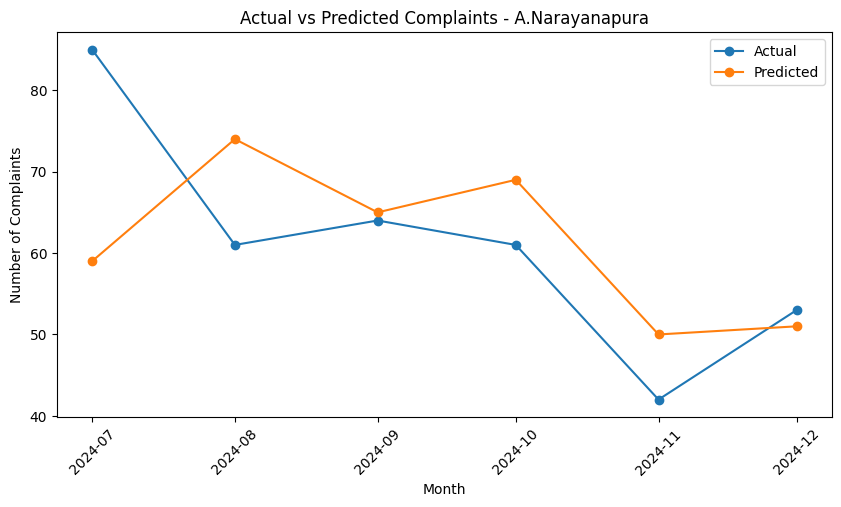

In [ ]:
import matplotlib.pyplot as plt

ward_result = results[results['ward'] == 'A.Narayanapura']

plt.figure(figsize=(10, 5))

plt.plot(ward_result['date'],
         ward_result['total_complaints'],
         marker='o', label='Actual')

plt.plot(ward_result['date'],
         ward_result['predicted_complaints'],
         marker='o', label='Predicted')

plt.title('Actual vs Predicted Complaints - A.Narayanapura')
plt.xlabel('Month')
plt.ylabel('Number of Complaints')
plt.legend()
plt.xticks(rotation=45)
plt.show()

In [ ]:
ward_errors = results.groupby('ward')['error'].mean().reset_index()

ward_errors = ward_errors.sort_values(
    by='error',
    ascending=False
)

ward_errors.head(10)

,ward,error
125,Maruthi Seva Nagar,120.000000
71,Horamavu,97.666667
42,Doddanekkundi,97.000000
18,Bellandur,86.833333
79,Jakkur,83.000000
87,Jnanabharathi Ward,80.000000
74,Hoysala Nagar,68.333333
66,Hemmigepura,64.500000
178,Thanisandra,64.500000
179,Ullalu,56.833333


In [ ]:
ward_performance = results.groupby('ward').agg(
    avg_actual=('total_complaints', 'mean'),
    avg_error=('error', 'mean')
).reset_index()

ward_performance['error_percent'] = (
    ward_performance['avg_error'] /
    ward_performance['avg_actual'].replace(0, np.nan)
) * 100

ward_performance = ward_performance.sort_values(
    by='error_percent',
    ascending=False
)

ward_performance.head(10)

,ward,avg_actual,avg_error,error_percent
125,Maruthi Seva Nagar,197.333333,120.000000,60.810811
166,Siddapura,47.833333,25.666667,53.658537
124,Maruthi Mandira Ward,37.000000,19.500000,52.702703
74,Hoysala Nagar,132.500000,68.333333,51.572327
3,Agrahara Dasarahalli,23.500000,11.833333,50.354610
56,Gurappanapalya,43.833333,21.166667,48.288973
89,K.R.Market,35.166667,15.166667,43.127962
113,Lakshmidevi Nagar,15.500000,6.666667,43.010753
128,Muneshwara Nagar,22.000000,9.333333,42.424242
77,Jagajeevanram Nagar,39.666667,16.666667,42.016807


In [ ]:
results[
    results['ward'] == 'Maruthi Seva Nagar'
][['date', 'total_complaints', 'predicted_complaints', 'error']]

,date,total_complaints,predicted_complaints,error
1890,2024-07-01,89,62.0,27.0
1891,2024-08-01,110,81.0,29.0
1892,2024-09-01,113,88.0,25.0
1893,2024-10-01,135,92.0,43.0
1894,2024-11-01,555,117.0,438.0
1895,2024-12-01,182,340.0,158.0


In [ ]:
november_complaints = complaints[
    (complaints['ward'] == 'Maruthi Seva Nagar') &
    (complaints['year'] == 2024) &
    (complaints['month'] == 11)
]

print("Total complaints:", len(november_complaints))

november_complaints['category'].value_counts()

Total complaints: 555


,count
category,
Road Maintenance(Engg),496
Electrical,26
Solid Waste (Garbage) Related,21
Health Dept,4
Sanitation,2
veterinary,2
Others,1
Forest,1
Road Infrastructure,1


In [ ]:
road_comparison = complaints[
    (complaints['ward'] == 'Maruthi Seva Nagar') &
    (complaints['year'] == 2024) &
    (complaints['month'].isin([10, 11]))
]

pd.crosstab(
    road_comparison['category'],
    road_comparison['month']
)

month,10,11
category,,
Electrical,29,26
Forest,8,1
Health Dept,6,4
Others,1,1
Revenue Department,1,0
Road Infrastructure,0,1
Road Maintenance(Engg),7,496
Sanitation,0,2
Solid Waste (Garbage) Related,79,21


In [ ]:
road_november = november_complaints[
    november_complaints['category'] == 'Road Maintenance(Engg)'
]

print("Total road complaints:", len(road_november))

road_november['subcategory'].value_counts().head(10)

Total road complaints: 496


,count
subcategory,
UnAuthorised Constructions,485
Potholes,5
Debris Removal / Construction Material,3
footpath encroachment,2
Road side drains,1


In [ ]:
construction_complaints = road_november[
    road_november['subcategory'] == 'UnAuthorised Constructions'
]

construction_complaints['grievance_date'].value_counts().sort_index()

,count
grievance_date,
2024-11-07 12:02:00,1
2024-11-14 09:37:00,1
2024-11-15 05:49:00,1
2024-11-16 08:14:00,1
2024-11-16 10:08:00,1
...,...
2024-11-30 09:52:00,1
2024-11-30 09:53:00,1
2024-11-30 11:49:00,1


In [ ]:
daily_complaints = construction_complaints.copy()

daily_complaints['day'] = daily_complaints['grievance_date'].dt.date

daily_complaints['day'].value_counts().sort_index()

,count
day,
2024-11-07,1
2024-11-14,1
2024-11-15,1
2024-11-16,2
2024-11-17,74
2024-11-18,2
2024-11-19,38
2024-11-20,2
2024-11-21,1


In [ ]:
print("Total complaints:", len(construction_complaints))

print("Unique complaint IDs:",
      construction_complaints['complaint_id'].nunique())

print("Duplicate complaint IDs:",
      construction_complaints['complaint_id'].duplicated().sum())

Total complaints: 485
Unique complaint IDs: 485
Duplicate complaint IDs: 0


In [ ]:
ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['year'] == 2024) &
    (ward_monthly['month'] == 11)
][['ward', 'date', 'total_complaints', 'z_score', 'anomaly']]

,ward,date,total_complaints,z_score,anomaly
1894,Maruthi Seva Nagar,2024-11-01,555,4.374263,-1


In [ ]:
def explain_anomaly(z):
    if z >= 3:
        return 'Very unusual increase in complaints'
    elif z >= 2:
        return 'Unusual increase in complaints'
    elif z <= -2:
        return 'Unusual decrease in complaints'
    else:
        return 'No major deviation from average'


ward_monthly['anomaly_explanation'] = (
    ward_monthly['z_score'].apply(explain_anomaly)
)

ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['year'] == 2024) &
    (ward_monthly['month'] == 11)
][['ward', 'total_complaints', 'z_score',
   'anomaly', 'anomaly_explanation']]

,ward,total_complaints,z_score,anomaly,anomaly_explanation
1894,Maruthi Seva Nagar,555,4.374263,-1,Very unusual increase in complaints


In [ ]:
monthly_categories = complaints.groupby(
    ['ward', 'year', 'month', 'category']
).size().reset_index(name='count')

monthly_categories = monthly_categories.sort_values(
    by='count',
    ascending=False
)

top_monthly_category = monthly_categories.drop_duplicates(
    subset=['ward', 'year', 'month']
)

top_monthly_category.head(10)

,ward,year,month,category,count
7681,Doddanekkundi,2024,1,Solid Waste (Garbage) Related,747
22684,Maruthi Seva Nagar,2024,11,Road Maintenance(Engg),496
16283,Jnanabharathi Ward,2024,12,Electrical,329
16192,Jnanabharathi Ward,2024,5,Electrical,324
16257,Jnanabharathi Ward,2024,10,Electrical,277
16270,Jnanabharathi Ward,2024,11,Electrical,273
16207,Jnanabharathi Ward,2024,6,Electrical,261
16245,Jnanabharathi Ward,2024,9,Electrical,258
31780,Ullalu,2024,5,Electrical,246
14846,Jakkur,2024,11,Electrical,242


In [ ]:
ward_monthly = ward_monthly.merge(
    top_monthly_category[
        ['ward', 'year', 'month', 'category', 'count']
    ],
    on=['ward', 'year', 'month'],
    how='left'
)

ward_monthly = ward_monthly.rename(
    columns={
        'category': 'main_category',
        'count': 'category_complaints'
    }
)

ward_monthly[
    ['ward', 'date', 'total_complaints',
     'main_category', 'category_complaints',
     'anomaly_explanation']
].head(10)

,ward,date,total_complaints,main_category,category_complaints,anomaly_explanation
0,A.Narayanapura,2023-01-01,29,Electrical,11.0,No major deviation from average
1,A.Narayanapura,2023-02-01,24,Solid Waste (Garbage) Related,13.0,No major deviation from average
2,A.Narayanapura,2023-03-01,40,Electrical,14.0,No major deviation from average
3,A.Narayanapura,2023-04-01,14,Solid Waste (Garbage) Related,5.0,No major deviation from average
4,A.Narayanapura,2023-05-01,16,Electrical,8.0,No major deviation from average
5,A.Narayanapura,2023-06-01,32,Road Maintenance(Engg),10.0,No major deviation from average
6,A.Narayanapura,2023-07-01,33,Road Maintenance(Engg),15.0,No major deviation from average
7,A.Narayanapura,2023-08-01,37,Electrical,14.0,No major deviation from average
8,A.Narayanapura,2023-09-01,34,Road Maintenance(Engg),13.0,No major deviation from average
9,A.Narayanapura,2023-10-01,36,Solid Waste (Garbage) Related,15.0,No major deviation from average


In [ ]:
def create_alert(row):

    if row['anomaly'] == -1:

        if pd.notna(row['category_complaints']):
            category = str(row['main_category'])
            count = int(row['category_complaints'])

            return (
                row['anomaly_explanation'] +
                ". Most reported category: " +
                category +
                " (" + str(count) + " complaints)"
            )

        else:
            return row['anomaly_explanation']

    else:
        return "No anomaly detected"


ward_monthly['detailed_alert'] = ward_monthly.apply(
    create_alert, axis=1
)

In [ ]:
ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['year'] == 2024) &
    (ward_monthly['month'] == 11)
][['ward', 'total_complaints', 'detailed_alert']]

,ward,total_complaints,detailed_alert
3022,Maruthi Seva Nagar,555,Very unusual increase in complaints. Most repo...


In [ ]:
alert = ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['year'] == 2024) &
    (ward_monthly['month'] == 11)
]

print(alert['detailed_alert'].iloc[0])

Very unusual increase in complaints. Most reported category: Road Maintenance(Engg) (496 complaints)


In [ ]:
monthly_subcategories = complaints.groupby(
    ['ward', 'year', 'month', 'subcategory']
).size().reset_index(name='subcategory_count')

monthly_subcategories = monthly_subcategories.sort_values(
    'subcategory_count', ascending=False
)

top_subcategory = monthly_subcategories.drop_duplicates(
    subset=['ward', 'year', 'month']
)

top_subcategory.head(10)

,ward,year,month,subcategory,subcategory_count
16728,Doddanekkundi,2024,1,Garbage transfer not as per norms & area not k...,733
49010,Maruthi Seva Nagar,2024,11,UnAuthorised Constructions,485
35591,Jnanabharathi Ward,2024,5,Street Light Not Working,315
35861,Jnanabharathi Ward,2024,12,Street Light Not Working,313
35784,Jnanabharathi Ward,2024,10,Street Light Not Working,271
35824,Jnanabharathi Ward,2024,11,Street Light Not Working,261
35634,Jnanabharathi Ward,2024,6,Street Light Not Working,252
35747,Jnanabharathi Ward,2024,9,Street Light Not Working,249
67613,Ullalu,2024,5,Street Light Not Working,240
26612,Hemmigepura,2024,11,Street Light Not Working,230


In [ ]:
ward_monthly = ward_monthly.merge(
    top_subcategory[
        ['ward', 'year', 'month',
         'subcategory', 'subcategory_count']
    ],
    on=['ward', 'year', 'month'],
    how='left'
)

In [ ]:
ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['year'] == 2024) &
    (ward_monthly['month'] == 11)
][['ward', 'total_complaints',
   'main_category', 'subcategory',
   'subcategory_count']]

,ward,total_complaints,main_category,subcategory,subcategory_count
3022,Maruthi Seva Nagar,555,Road Maintenance(Engg),UnAuthorised Constructions,485.0


In [ ]:
def create_alert(row):

    if row['anomaly'] == -1:

        alert = row['anomaly_explanation']

        if pd.notna(row['subcategory_count']):

            alert += (
                ". Most reported issue: " +
                str(row['subcategory']) +
                " (" + str(int(row['subcategory_count'])) +
                " complaints)"
            )

        return alert

    else:
        return "No anomaly detected"


ward_monthly['detailed_alert'] = ward_monthly.apply(
    create_alert, axis=1
)

In [ ]:
alert = ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['year'] == 2024) &
    (ward_monthly['month'] == 11)
]

print(alert['detailed_alert'].iloc[0])

Very unusual increase in complaints. Most reported issue: UnAuthorised Constructions (485 complaints)


In [ ]:
comparison = complaints[
    (complaints['ward'] == 'Maruthi Seva Nagar') &
    (complaints['year'] == 2024) &
    (complaints['month'].isin([10, 11]))
]

comparison = pd.crosstab(
    comparison['subcategory'],
    comparison['month']
)

comparison = comparison.reindex(
    columns=[10, 11], fill_value=0
)

comparison['increase'] = comparison[11] - comparison[10]

comparison.sort_values('increase', ascending=False).head(10)

month,10,11,increase
subcategory,,,
UnAuthorised Constructions,0,485,485
Potholes,1,5,4
Debris Removal / Construction Material,1,3,2
Stray/Rabid dog bite,0,1,1
Public toilet(s) blockage,0,1,1
Requirement For New Street Lights,0,1,1
Street Lights Switched On During Day Time,0,1,1
Road Infrastructure,0,1,1
Earthing Issue relate to Electric Poles/Panel Boards,0,1,1


In [ ]:
subcategory_monthly = complaints.groupby(
    ['ward', 'date', 'subcategory']
).size().reset_index(name='complaints')

KeyError: 'date'

In [ ]:
subcategory_monthly = complaints.groupby(
    ['ward', 'year', 'month', 'subcategory']
).size().reset_index(name='complaints')

subcategory_monthly['date'] = pd.to_datetime(
    subcategory_monthly[['year', 'month']].assign(day=1)
)

subcategory_monthly.head()

,ward,year,month,subcategory,complaints,date
0,A.Narayanapura,2023,1,Dead animal(s),1,2023-01-01
1,A.Narayanapura,2023,1,Debris Removal / Construction Material,2,2023-01-01
2,A.Narayanapura,2023,1,Garbage vehicle not arrived,10,2023-01-01
3,A.Narayanapura,2023,1,Others,1,2023-01-01
4,A.Narayanapura,2023,1,Road Infrastructure,1,2023-01-01


In [ ]:
subcategory_monthly = subcategory_monthly.sort_values(
    ['ward', 'subcategory', 'date']
)

subcategory_monthly = (
    subcategory_monthly.set_index('date')
    .groupby(['ward', 'subcategory'])['complaints']
    .resample('MS')
    .sum()
    .reset_index()
)

subcategory_monthly['previous_month'] = (
    subcategory_monthly.groupby(
        ['ward', 'subcategory']
    )['complaints'].shift(1)
)

subcategory_monthly['increase'] = (
    subcategory_monthly['complaints'] -
    subcategory_monthly['previous_month']
)

subcategory_monthly.head(10)

,ward,subcategory,date,complaints,previous_month,increase
0,A.Narayanapura,Air/Noise pollution,2024-05-01,1,NaN,NaN
1,A.Narayanapura,Air/Noise pollution,2024-06-01,1,1.0,0.0
2,A.Narayanapura,Air/Noise pollution,2024-07-01,1,1.0,0.0
3,A.Narayanapura,Air/Noise pollution,2024-08-01,0,1.0,-1.0
4,A.Narayanapura,Air/Noise pollution,2024-09-01,1,0.0,1.0
5,A.Narayanapura,Air/Noise pollution,2024-10-01,4,1.0,3.0
6,A.Narayanapura,Animal birth control/neutering of stray dogs,2023-03-01,4,NaN,NaN
7,A.Narayanapura,Animal birth control/neutering of stray dogs,2023-04-01,0,4.0,-4.0
8,A.Narayanapura,Animal birth control/neutering of stray dogs,2023-05-01,0,0.0,0.0
9,A.Narayanapura,Animal birth control/neutering of stray dogs,2023-06-01,0,0.0,0.0


In [ ]:
subcategory_monthly[
    (subcategory_monthly['ward'] == 'Maruthi Seva Nagar') &
    (subcategory_monthly['subcategory'] == 'UnAuthorised Constructions') &
    (subcategory_monthly['date'] >= '2024-10-01') &
    (subcategory_monthly['date'] <= '2024-11-01')
]


,ward,subcategory,date,complaints,previous_month,increase
94508,Maruthi Seva Nagar,UnAuthorised Constructions,2024-10-01,0,1.0,-1.0
94509,Maruthi Seva Nagar,UnAuthorised Constructions,2024-11-01,485,0.0,485.0


In [ ]:
top_increases = subcategory_monthly.sort_values(
    'increase', ascending=False
)

top_increases = top_increases.drop_duplicates(
    subset=['ward', 'date']
)

top_increases.head(10)

,ward,subcategory,date,complaints,previous_month,increase
31692,Doddanekkundi,Garbage transfer not as per norms & area not k...,2024-01-01,733,159.0,574.0
94509,Maruthi Seva Nagar,UnAuthorised Constructions,2024-11-01,485,0.0,485.0
67605,Jnanabharathi Ward,Street Light Not Working,2024-05-01,315,141.0,174.0
31691,Doddanekkundi,Garbage transfer not as per norms & area not k...,2023-12-01,159,0.0,159.0
57380,Hoysala Nagar,Garbage dump,2024-06-01,139,11.0,128.0
131465,Ullalu,Street Light Not Working,2024-05-01,240,117.0,123.0
50527,Hemmigepura,Street Light Not Working,2024-05-01,209,106.0,103.0
79521,Kodigehalli,water stagnation,2024-10-01,99,0.0,99.0
29044,Dharmarayaswamy Temple Ward,Garbage dump,2024-10-01,132,34.0,98.0
134567,Varthur,Garbage vehicle not arrived,2023-11-01,101,12.0,89.0


In [ ]:
all_months = pd.date_range(
    start='2023-01-01',
    end='2024-12-01',
    freq='MS'
)

print("Total months:", len(all_months))
print(all_months)

Total months: 24
DatetimeIndex(['2023-01-01', '2023-02-01', '2023-03-01', '2023-04-01',
               '2023-05-01', '2023-06-01', '2023-07-01', '2023-08-01',
               '2023-09-01', '2023-10-01', '2023-11-01', '2023-12-01',
               '2024-01-01', '2024-02-01', '2024-03-01', '2024-04-01',
               '2024-05-01', '2024-06-01', '2024-07-01', '2024-08-01',
               '2024-09-01', '2024-10-01', '2024-11-01', '2024-12-01'],
              dtype='datetime64[ns]', freq='MS')


In [ ]:
# Create all ward-subcategory combinations
pairs = subcategory_monthly[
    ['ward', 'subcategory']
].drop_duplicates()

# Create all combinations with 24 months
full_data = pairs.merge(
    pd.DataFrame({'date': all_months}),
    how='cross'
)

# Add the actual complaint counts
full_data = full_data.merge(
    subcategory_monthly[
        ['ward', 'subcategory', 'date', 'complaints']
    ],
    on=['ward', 'subcategory', 'date'],
    how='left'
)

# Fill missing counts with zero
full_data['complaints'] = (
    full_data['complaints'].fillna(0).astype(int)
)

print("Total rows:", len(full_data))
full_data.head()

Total rows: 291912


,ward,subcategory,date,complaints
0,A.Narayanapura,Air/Noise pollution,2023-01-01,0
1,A.Narayanapura,Air/Noise pollution,2023-02-01,0
2,A.Narayanapura,Air/Noise pollution,2023-03-01,0
3,A.Narayanapura,Air/Noise pollution,2023-04-01,0
4,A.Narayanapura,Air/Noise pollution,2023-05-01,0


In [ ]:
# Sort data by ward, subcategory and date
full_data = full_data.sort_values(
    ['ward', 'subcategory', 'date']
)

# Get previous month's complaints
full_data['previous_month'] = full_data.groupby(
    ['ward', 'subcategory']
)['complaints'].shift(1)

# Calculate increase
full_data['increase'] = (
    full_data['complaints'] - full_data['previous_month']
)

full_data.head(10)

,ward,subcategory,date,complaints,previous_month,increase
0,A.Narayanapura,Air/Noise pollution,2023-01-01,0,NaN,NaN
1,A.Narayanapura,Air/Noise pollution,2023-02-01,0,0.0,0.0
2,A.Narayanapura,Air/Noise pollution,2023-03-01,0,0.0,0.0
3,A.Narayanapura,Air/Noise pollution,2023-04-01,0,0.0,0.0
4,A.Narayanapura,Air/Noise pollution,2023-05-01,0,0.0,0.0
5,A.Narayanapura,Air/Noise pollution,2023-06-01,0,0.0,0.0
6,A.Narayanapura,Air/Noise pollution,2023-07-01,0,0.0,0.0
7,A.Narayanapura,Air/Noise pollution,2023-08-01,0,0.0,0.0
8,A.Narayanapura,Air/Noise pollution,2023-09-01,0,0.0,0.0
9,A.Narayanapura,Air/Noise pollution,2023-10-01,0,0.0,0.0


In [ ]:
full_data[
    (full_data['ward'] == 'Maruthi Seva Nagar') &
    (full_data['subcategory'] == 'UnAuthorised Constructions') &
    (full_data['date'].isin(['2024-10-01', '2024-11-01']))
][['date', 'complaints', 'previous_month', 'increase']]

/tmp/ipykernel_481/797549708.py:4: FutureWarning: The behavior of 'isin' with dtype=datetime64[ns] and castable values (e.g. strings) is deprecated. In a future version, these will not be considered matching by isin. Explicitly cast to the appropriate dtype before calling isin instead.
  (full_data['date'].isin(['2024-10-01', '2024-11-01']))


,date,complaints,previous_month,increase
188829,2024-10-01,0,1.0,-1.0
188830,2024-11-01,485,0.0,485.0


In [ ]:
top_increases = full_data.sort_values(
    'increase', ascending=False
)

top_increases = top_increases.drop_duplicates(
    subset=['ward', 'date']
)

top_increases = top_increases[
    top_increases['increase'] > 0
]

top_increases.head(10)

,ward,subcategory,date,complaints,previous_month,increase
63996,Doddanekkundi,Garbage transfer not as per norms & area not k...,2024-01-01,733,159.0,574.0
188830,Maruthi Seva Nagar,UnAuthorised Constructions,2024-11-01,485,0.0,485.0
28194,Bellandur,Dengue positive,2024-07-01,190,0.0,190.0
133984,Jnanabharathi Ward,Street Light Not Working,2024-05-01,315,141.0,174.0
63995,Doddanekkundi,Garbage transfer not as per norms & area not k...,2023-12-01,159,0.0,159.0
114425,Hoysala Nagar,Garbage dump,2024-06-01,139,11.0,128.0
263008,Ullalu,Street Light Not Working,2024-05-01,240,117.0,123.0
101512,Hemmigepura,Street Light Not Working,2024-05-01,209,106.0,103.0
158061,Kodigehalli,water stagnation,2024-10-01,99,0.0,99.0
58773,Dharmarayaswamy Temple Ward,Garbage dump,2024-10-01,132,34.0,98.0


In [ ]:
# Select the columns we need
increase_data = top_increases[
    ['ward', 'date', 'subcategory', 'increase']
].copy()

# Rename columns
increase_data = increase_data.rename(
    columns={
        'subcategory': 'increased_issue',
        'increase': 'issue_increase'
    }
)

# Merge with our anomaly dataset
ward_monthly = ward_monthly.merge(
    increase_data,
    on=['ward', 'date'],
    how='left'
)

ward_monthly.head()

,ward,date,year,month,total_complaints,avg_complaints,deviation,std_complaints,z_score,anomaly,previous_month_complaints,previous_3month_avg,anomaly_explanation,main_category,category_complaints,detailed_alert,subcategory,subcategory_count,increased_issue,issue_increase
0,A.Narayanapura,2023-01-01,2023,1,29,40.75,-11.75,16.65311,-0.705574,1,NaN,NaN,No major deviation from average,Electrical,11.0,No anomaly detected,Street Light Not Working,10.0,NaN,NaN
1,A.Narayanapura,2023-02-01,2023,2,24,40.75,-16.75,16.65311,-1.005818,1,29.0,NaN,No major deviation from average,Solid Waste (Garbage) Related,13.0,No anomaly detected,Street Light Not Working,7.0,Garbage dumping in vacant sites,2.0
2,A.Narayanapura,2023-03-01,2023,3,40,40.75,-0.75,16.65311,-0.045037,1,24.0,NaN,No major deviation from average,Electrical,14.0,No anomaly detected,Street Light Not Working,14.0,Street Light Not Working,7.0
3,A.Narayanapura,2023-04-01,2023,4,14,40.75,-26.75,16.65311,-1.606307,-1,40.0,31.0,No major deviation from average,Solid Waste (Garbage) Related,5.0,No major deviation from average. Most reported...,Street Light Not Working,4.0,obstructions Branches / Trees.,1.0
4,A.Narayanapura,2023-05-01,2023,5,16,40.75,-24.75,16.65311,-1.486209,1,14.0,26.0,No major deviation from average,Electrical,8.0,No anomaly detected,Street Light Not Working,8.0,Street Light Not Working,4.0


In [ ]:
ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['date'] == '2024-11-01')
][['ward', 'total_complaints',
   'increased_issue', 'issue_increase']]

,ward,total_complaints,increased_issue,issue_increase
3022,Maruthi Seva Nagar,555,UnAuthorised Constructions,485.0


In [ ]:
def create_alert(row):

    if row['anomaly'] == -1:

        if row['z_score'] >= 2:

            alert = "Unusual increase in complaints"

            if pd.notna(row['issue_increase']):

                alert += (
                    ". Largest increase: " +
                    str(row['increased_issue']) +
                    " (+" + str(int(row['issue_increase'])) +
                    " complaints)"
                )

            return alert

        elif row['z_score'] <= -2:

            return "Unusual decrease in complaints"

        else:

            return "Unusual complaint pattern detected"

    else:

        return "No anomaly detected"


ward_monthly['final_alert'] = ward_monthly.apply(
    create_alert, axis=1
)

In [ ]:
alert = ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['date'] == '2024-11-01')
]

print(alert['final_alert'].iloc[0])

Unusual increase in complaints. Largest increase: UnAuthorised Constructions (+485 complaints)


In [ ]:
def recommend_action(issue):

    if pd.isna(issue):
        return "Review complaint records"

    issue = str(issue).lower()

    if 'construction' in issue:
        return "Verify construction permissions and inspect reported sites"

    elif 'street light' in issue:
        return "Inspect and repair reported streetlights"

    elif 'garbage' in issue:
        return "Inspect garbage collection and disposal services"

    elif 'pothole' in issue:
        return "Inspect roads and prioritize pothole repairs"

    elif 'dengue' in issue:
        return "Refer complaints to public health officials for verification"

    else:
        return "Review the reported issue and assign the relevant department"


ward_monthly['suggested_action'] = (
    ward_monthly['increased_issue'].apply(recommend_action)
)

In [ ]:
result = ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['date'] == '2024-11-01')
]

print("Alert:", result['final_alert'].iloc[0])
print("Recommendation:", result['suggested_action'].iloc[0])

Alert: Unusual increase in complaints. Largest increase: UnAuthorised Constructions (+485 complaints)
Recommendation: Verify construction permissions and inspect reported sites


In [ ]:
priority_data = ward_summary[
    ['ward', 'priority_score', 'priority_level']
].copy()

ward_monthly = ward_monthly.merge(
    priority_data,
    on='ward',
    how='left'
)

ward_monthly[
    ['ward', 'date', 'total_complaints',
     'priority_score', 'priority_level',
     'final_alert', 'suggested_action']
].head()

,ward,date,total_complaints,priority_score,priority_level,final_alert,suggested_action
0,A.Narayanapura,2023-01-01,29,23.964253,Low,No anomaly detected,Review complaint records
1,A.Narayanapura,2023-02-01,24,23.964253,Low,No anomaly detected,Inspect garbage collection and disposal services
2,A.Narayanapura,2023-03-01,40,23.964253,Low,No anomaly detected,Inspect and repair reported streetlights
3,A.Narayanapura,2023-04-01,14,23.964253,Low,Unusual complaint pattern detected,Review the reported issue and assign the relev...
4,A.Narayanapura,2023-05-01,16,23.964253,Low,No anomaly detected,Inspect and repair reported streetlights


In [ ]:
def action_assessment(row):

    if row['anomaly'] == -1 and row['z_score'] >= 2:
        return "Investigate unusual complaint increase"

    elif row['anomaly'] == -1:
        return "Review unusual complaint pattern"

    elif row['priority_level'] == 'High':
        return "High historical priority - routine monitoring"

    elif row['priority_level'] == 'Medium':
        return "Medium historical priority - routine monitoring"

    else:
        return "Routine monitoring"


ward_monthly['action_assessment'] = ward_monthly.apply(
    action_assessment, axis=1
)

In [ ]:
result = ward_monthly[
    (ward_monthly['ward'] == 'Maruthi Seva Nagar') &
    (ward_monthly['date'] == '2024-11-01')
]

print("Historical Priority:", result['priority_level'].iloc[0])
print("Alert:", result['final_alert'].iloc[0])
print("Assessment:", result['action_assessment'].iloc[0])
print("Suggested Action:", result['suggested_action'].iloc[0])

Historical Priority: Medium
Alert: Unusual increase in complaints. Largest increase: UnAuthorised Constructions (+485 complaints)
Assessment: Investigate unusual complaint increase
Suggested Action: Verify construction permissions and inspect reported sites


In [ ]:
dashboard_data = ward_monthly[
    ['ward', 'date', 'total_complaints',
     'priority_score', 'priority_level',
     'anomaly', 'final_alert',
     'increased_issue', 'issue_increase',
     'suggested_action', 'action_assessment']
].copy()

dashboard_data.head()

,ward,date,total_complaints,priority_score,priority_level,anomaly,final_alert,increased_issue,issue_increase,suggested_action,action_assessment
0,A.Narayanapura,2023-01-01,29,23.964253,Low,1,No anomaly detected,NaN,NaN,Review complaint records,Routine monitoring
1,A.Narayanapura,2023-02-01,24,23.964253,Low,1,No anomaly detected,Garbage dumping in vacant sites,2.0,Inspect garbage collection and disposal services,Routine monitoring
2,A.Narayanapura,2023-03-01,40,23.964253,Low,1,No anomaly detected,Street Light Not Working,7.0,Inspect and repair reported streetlights,Routine monitoring
3,A.Narayanapura,2023-04-01,14,23.964253,Low,-1,Unusual complaint pattern detected,obstructions Branches / Trees.,1.0,Review the reported issue and assign the relev...,Review unusual complaint pattern
4,A.Narayanapura,2023-05-01,16,23.964253,Low,1,No anomaly detected,Street Light Not Working,4.0,Inspect and repair reported streetlights,Routine monitoring


In [ ]:
print("Total rows:", len(dashboard_data))

print("Total wards:", dashboard_data['ward'].nunique())

print("\nMissing values:")
print(dashboard_data.isnull().sum())

print("\nDuplicate ward-month records:")
print(dashboard_data.duplicated(['ward', 'date']).sum())

Total rows: 4752
Total wards: 198

Missing values:
ward                   0
date                   0
total_complaints       0
priority_score         0
priority_level         0
anomaly                0
final_alert            0
increased_issue      214
issue_increase       214
suggested_action       0
action_assessment      0
dtype: int64

Duplicate ward-month records:
0


In [ ]:
dashboard_data.to_csv(
    'civicpulse_dashboard.csv',
    index=False
)

print("Dashboard dataset saved successfully!")

Dashboard dataset saved successfully!


In [ ]:
from google.colab import files

files.download('civicpulse_dashboard.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>